In [15]:
#!pip install nltk
#!pip install PyPDF2
#!pip install gensim
#!pip install fitz
#!pip install PyMuPDF nltk


In [18]:
import os
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import PyPDF2
from gensim import corpora, models
import fitz
import re


In [24]:
# Path to the data folder containing PDFs
data_folder = "Data"

# Process each PDF in the folder
pdf_texts = []
for pdf_file in os.listdir(data_folder):
    if pdf_file.endswith(".pdf"):
        pdf_path = os.path.join(data_folder, pdf_file)
        with fitz.open(pdf_path) as doc:
            pdf_text = ""
            for page in doc:
                pdf_text += page.get_text()
            pdf_texts.append(pdf_text)

# Tokenization and sentence splitting
sentences = [sent_tokenize(pdf_text) for pdf_text in pdf_texts]
tokens = [word_tokenize(sentence) for pdf_sentences in sentences for sentence in pdf_sentences]

# Stopwords removal and stemming
nltk.download('punkt')
nltk.download('stopwords')
ps = PorterStemmer()
stop_words = set(stopwords.words('english'))

cleaned_tokens = []
for sentence_tokens in tokens:
    cleaned_tokens.append([ps.stem(token) for token in sentence_tokens if token.lower() not in stop_words])

# Create a dictionary and corpus for topic modeling
dictionary = corpora.Dictionary(cleaned_tokens)
corpus = [dictionary.doc2bow(tokens) for tokens in cleaned_tokens]

# Topic Modeling using LDA
lda_model = models.LdaModel(corpus, num_topics=10, id2word=dictionary)

# Print topics and words
for idx, topic in lda_model.print_topics(-1):
    print(f"Topic: {idx}")
    print(f"Words: {topic}\n")

# Extracted entities from cleaned_tokens
entities = set()
for sentence_tokens in cleaned_tokens:
    for token in sentence_tokens:
        # Normalize entity names by converting to lowercase and removing special characters
        normalized_entity = re.sub(r'[^a-zA-Z0-9\s]', '', token.lower())
        entities.add(normalized_entity)

# Knowledge Graph Construction (improved)
knowledge_graph = {}
for idx, topic in lda_model.print_topics(-1):
    related_entities = set()
    for word, _ in lda_model.show_topic(idx):
        # Normalize word for comparison
        normalized_word = re.sub(r'[^a-zA-Z0-9\s]', '', word.lower())
        # Use valid entities in the knowledge graph (you can skip this if you don't have an external source)
        related_entities.update([entity for entity in entities if normalized_word in entity])
    knowledge_graph[f"Topic {idx}"] = list(related_entities)

# Print results
print("Entities:", entities)
print("Knowledge Graph:", knowledge_graph)


[nltk_data] Downloading package punkt to /Users/neupanek/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/neupanek/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Topic: 0
Words: 0.054*"," + 0.044*"." + 0.013*"knowledg" + 0.010*"attack" + 0.009*")" + 0.009*"threat" + 0.009*"(" + 0.009*"data" + 0.008*"oper" + 0.008*"graph"

Topic: 1
Words: 0.059*"." + 0.027*"," + 0.014*"adversari" + 0.010*"intrus" + 0.009*"access" + 0.008*"intellig" + 0.008*"exploit" + 0.008*"method" + 0.007*"observ" + 0.006*"crowdstrik"

Topic: 2
Words: 0.062*"." + 0.051*"," + 0.012*"(" + 0.012*")" + 0.010*"attack" + 0.010*"[" + 0.010*"]" + 0.010*"et" + 0.009*"2022" + 0.009*"al"

Topic: 3
Words: 0.063*"," + 0.042*"." + 0.039*"]" + 0.039*"[" + 0.012*"secur" + 0.011*"threat" + 0.010*"knowledg" + 0.010*"data" + 0.009*"cyber" + 0.009*")"

Topic: 4
Words: 0.118*"," + 0.048*"." + 0.019*"attack" + 0.010*"network" + 0.010*"secur" + 0.008*"]" + 0.008*"[" + 0.007*"kg" + 0.007*"technolog" + 0.007*"vulner"

Topic: 5
Words: 0.045*"." + 0.039*"," + 0.013*"vulner" + 0.009*"graph" + 0.008*"method" + 0.008*"[" + 0.007*"attack" + 0.007*"]" + 0.007*"network" + 0.007*"kg"

Topic: 6
Words: 0.095*","

In [25]:
entities

{'',
 'fourth',
 'key',
 'unstructur',
 'li',
 'fulli',
 'moreov',
 'foreign',
 'novel',
 'jone',
 'elsevi',
 'lead',
 'segment',
 'juli',
 'timetovalu',
 'deliv',
 'vulkg',
 'uco',
 'shelter',
 'zyde',
 'tradecraft',
 'followon',
 'pretens',
 '68',
 'ransom',
 'patriot',
 'custom',
 'compon',
 'fragment',
 'facebook',
 'shutdown',
 'outcom',
 'feed',
 'credenti',
 'strong',
 '242248',
 'externalfac',
 'threatquoti',
 'decemb',
 'vs',
 'evolv',
 'exist',
 'probabl',
 '12',
 'screenconnect',
 'buffalo',
 'file',
 'propos',
 'remain',
 'a',
 'unparallel',
 'disclos',
 'lab',
 'record',
 'snort',
 'known',
 'inaccur',
 'conflict',
 'area',
 'w3orgtrowlguid',
 'privat',
 'east',
 'defens',
 'broadli',
 'bilstmcrf',
 'longperiod',
 'technolog',
 'cskg',
 'hour',
 'crucial',
 'port',
 'promptbas',
 'black',
 'alshaer',
 'infrastructur',
 'coloni',
 'undoubtedli',
 '27354',
 'xdr',
 'antiforens',
 'simul',
 '206',
 'hooi',
 'difficulti',
 'detect',
 'visit',
 'imit',
 'often',
 'leverag',
 'm

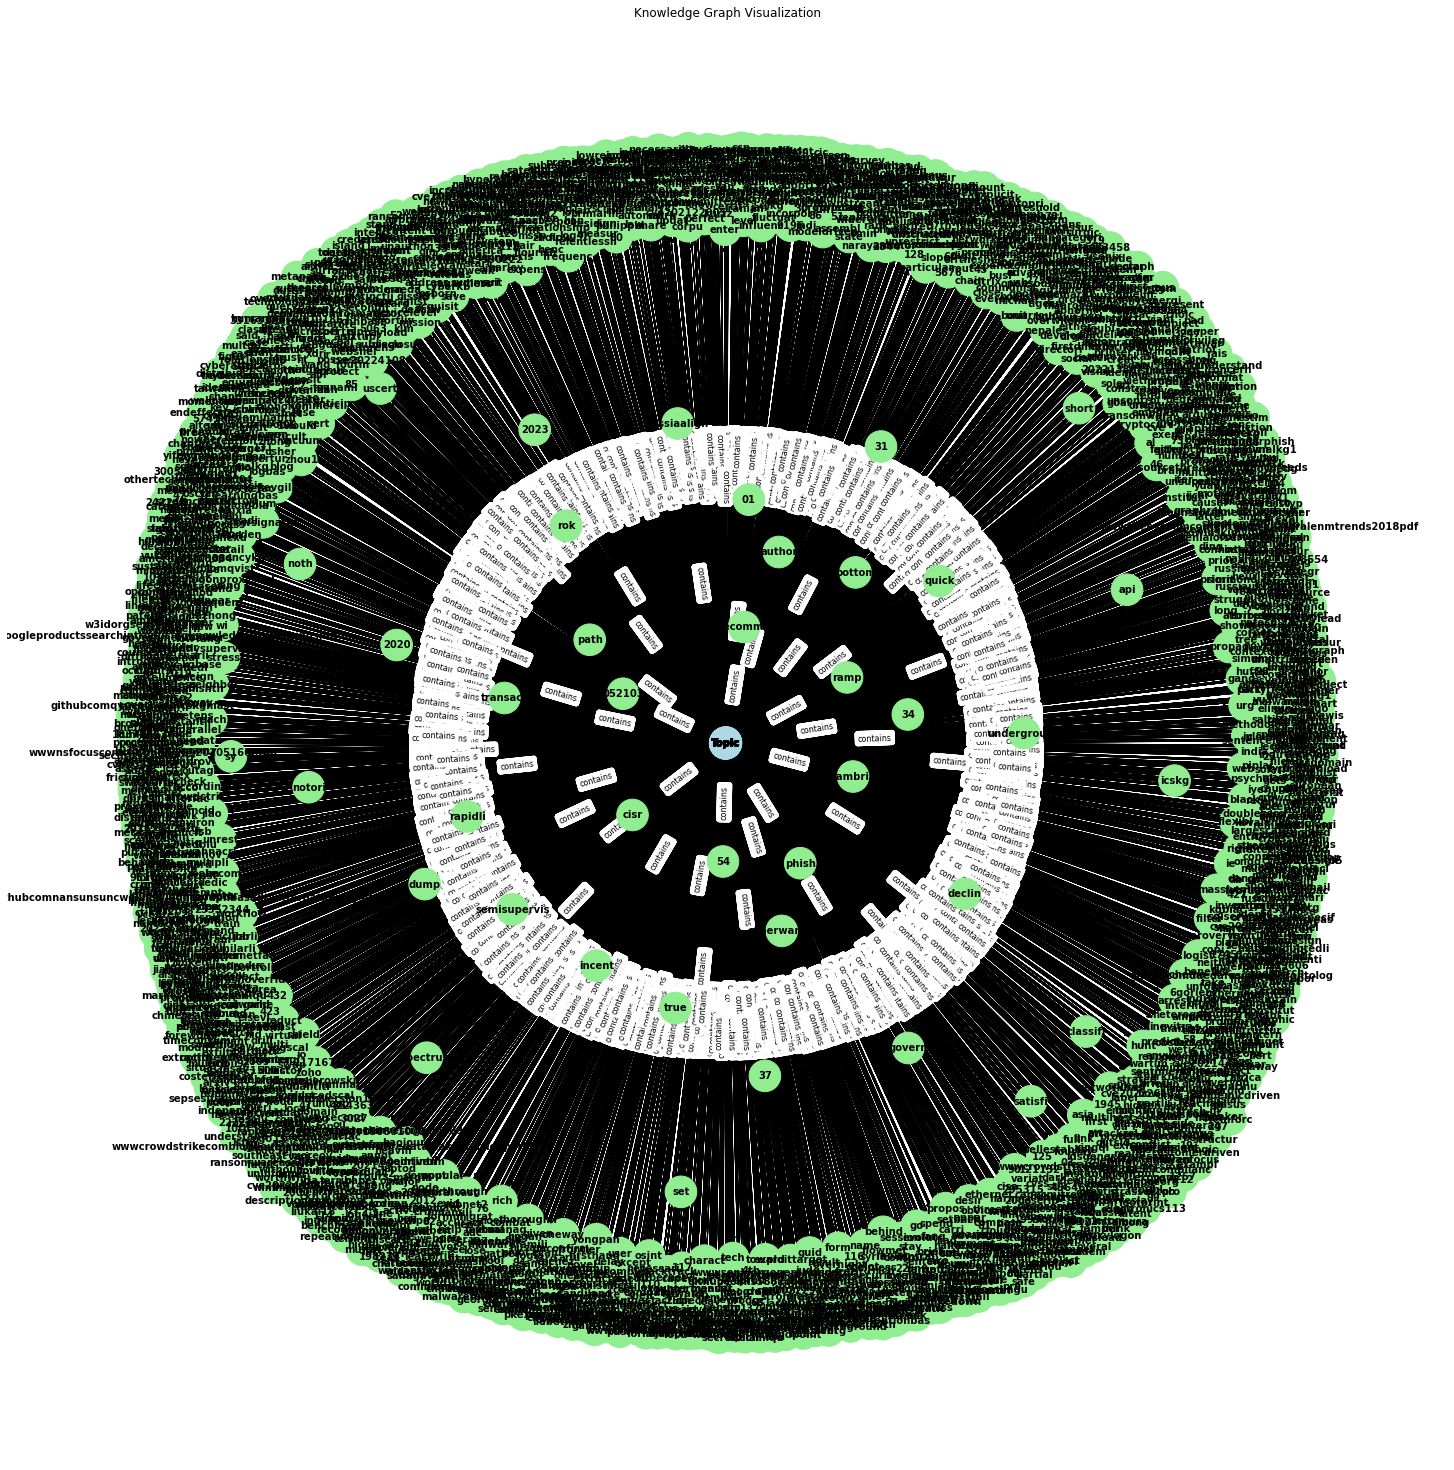

In [26]:
G = nx.DiGraph()

# Add nodes for topics and entities
for topic, entities in knowledge_graph.items():
    G.add_node(topic, node_type='topic')
    for entity in entities:
        G.add_node(entity, node_type='entity')
        G.add_edge(topic, entity, relation='contains')

# Define node colors and labels
node_colors = {'topic': 'lightblue', 'entity': 'lightgreen'}
node_labels = {node: node for node in G.nodes()}

# Create a larger figure
plt.figure(figsize=(20, 20))  # Adjust the width and height as needed

# Define a function to remove punctuations and single letters from entities
def clean_entity(entity):
    entity = ''.join(char for char in entity if char not in string.punctuation)  # Remove punctuations
    entity = ' '.join(word for word in entity.split() if len(word) > 1)  # Remove single letters
    return entity

# Clean the entities before plotting
cleaned_entities = {entity: clean_entity(entity) for entity in G.nodes()}

# Draw the graph
pos = nx.spring_layout(G, seed=42)  # Define node positions
node_color = [node_colors[G.nodes[node]['node_type']] for node in G.nodes()]
labels = {node: cleaned_entities[node] for node in G.nodes()}  # Use cleaned labels

nx.draw(G, pos, node_color=node_color, labels=labels, with_labels=True, node_size=1000, font_size=10, font_color="black", font_weight="bold")

# Add edge labels (optional)
edge_labels = {(u, v): G[u][v]['relation'] for u, v in G.edges()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)

plt.title("Knowledge Graph Visualization")
plt.show()

In [1]:
import requests
from lxml import etree
import time
import csv


In [2]:
Tactics_info_list = []

Techniques_info_list = []
Techniques_url = []

Mitigations_info_list = []
Mitigations_info_list_temp = []
Mitigations_url = []

Groups_info_list = []
Groups_info_list_temp = []
Groups_url = []